# AI 최적화 & 엔지니어링

지금까지: 퍼셉트론 → 역전파 → CNN → RNN → 트랜스포머 → LLM → 생성모델
- 이제 질문: **"AI가 더 잘 일하게 하려면?"**

- 모델 안 바꾸기
  - 전이학습, 경량화: 이미 만든 모델 효율적으로 쓰기
  - 정렬: 사람 의도에 맞게 행동시키기
- 모델 바깥 바꾸기
  - 프롬프트: 입력
  - 하네스: 환경
  - 루프: 반복

# 전이학습

- 왜 필요? X-ray 100장으로 폐렴 분류 모델 만들면
  - 데이터 부족 → 패턴 못 배움
  - 과적합 → 새 환자 사진 못 맞춤
  - 처음부터 학습 → 시간, 돈 많이 듦
- 그래서 수백만 장 본 모델의 "보는 눈"을 빌려옴

### 전이학습이란
- **사전학습 모델이 배운 능력을 새 작업에 재활용하는 것**

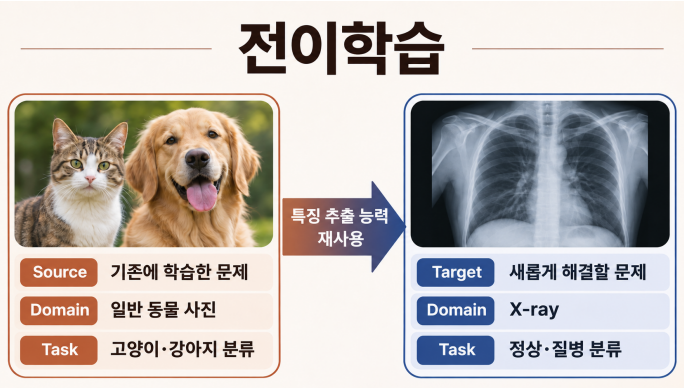

- 과정
  1. 동물 사진으로 사전학습 → 윤곽, 질감 찾는 법이 가중치에 담김
  2. 분류층만 정상/폐렴용으로 교체
  3. X-ray로 새 분류층 학습
  4. 필요하면 fine-tuning
- 용어
  - Source: 원래 배운 문제 / Target: 새 문제
  - Domain: 데이터 특성 / Task: 하려는 작업
  - Domain이나 Task 중 하나라도 다르면 전이학습

### 분류
- Domain, Task 기준
  - 귀납적: Task 다름. Target 라벨 필수 (이미지 분류 → 객체 탐지)
  - 변환적: Domain만 다름. Target 라벨 x (뉴스 감정 → 영화 리뷰 감정)
  - 비지도: 둘 다 라벨 x (군집화 → 다른 분야 군집화)
- 뭘 가져오냐 기준
  - 인스턴스(데이터) / 특성(특징 표현) / 파라미터(가중치) / 관계(관계 패턴)

### 전이학습의 변화
- 예전
  - 이미지: ImageNet으로 CNN 학습 → 가중치 재사용
  - 언어: 단어 벡터 재사용. 근데 "배"(과일)랑 "배"(탈것) 구분 x
- 트랜스포머 이후
  - 이미지: 가린 부분 복원하며 학습 → 라벨 없어도 ㄱㄴ
  - 언어: BERT(빈칸 맞히기), GPT(다음 단어 맞히기) → 문맥 보고 "배" 구분 ㄱㄴ

### Foundation Model
- 여러 작업의 출발점이 되는 거대 사전학습 모델
- 하나로 상담 모델, 요약 모델 등 여러 개 만듦
- vs 사전학습 모델
  - FM: "여러 작업에 쓸 수 있냐"에 초점
  - 사전학습 모델: "뭘로 미리 배웠냐"에 초점

### Fine-tuning

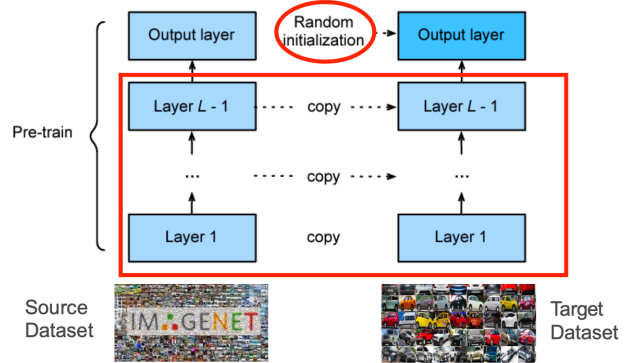

- 사전학습 모델을 새 데이터로 추가 학습해서 가중치 조정
- 과정: 특징 추출 → 예측 → 오차 계산 → 역전파로 업데이트
- 모든 가중치 바꿀 필요 x

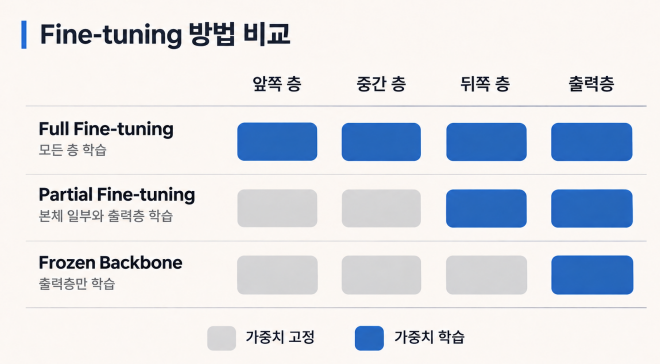

  - Full: 전부 학습. 제일 많이 바뀌지만 비싸고 기존 지식 까먹을 수 있음
  - Partial: 앞쪽 층 고정, 뒤쪽만 학습
    - 앞쪽 층 = 선, 윤곽 같은 범용 특징
    - 뒤쪽 층 = 작업 특화 특징
  - Frozen Backbone: 분류층만 학습. 제일 싸지만 한계 있음
- 고르는 법
  - 데이터 적음: 도메인 비슷하면 Frozen, 다르면 Partial
  - 데이터 많음: 도메인 비슷하면 Partial, 다르면 Full

### PEFT
- 거대 모델은 일부 층만 바꿔도 양이 너무 많음
- → 대부분 고정하고 **아주 조금만** 학습
- 장점: 메모리 ↓, 모델 1개 + 작업별 작은 파일만 저장
- LoRA: 원래 가중치 W는 고정, 수정분 ΔW를 작은 행렬 두 개(B×A)로 학습
  - 1000×1000이면 원래 100만 개 → r=8이면 1만 6천 개
  - r 크면 표현력 ↑, 비용 ↑
- Adapter: 모델 중간에 작은 신경망 끼우고 그것만 학습
- Prompt tuning: 입력 앞에 학습용 벡터 붙이고 그것만 학습
- Zero-shot / Few-shot: 학습 아예 x, 입력만 바꿈 (프롬프트에서 자세히)

### 한계
- Negative Transfer: 전이했더니 오히려 성능 ↓
  - 동물 털 질감 특징이 X-ray엔 방해
  - MMD: Source, Target 분포가 얼마나 다른지 보는 지표
- Catastrophic Forgetting: 새 거 배우다 옛날 거 까먹음
  - EWC: 중요한 가중치가 많이 바뀌면 벌점
- Bias Transfer: 사전학습 데이터의 편향이 그대로 넘어옴
- Transferability: 어떤 모델이 잘 맞을지 미리 알기 어려움
  - LEEP: 기존 모델의 예측 확률로 추정
  - LogME: 기존 모델이 뽑은 특징으로 추정

# 경량화

- 왜? 큰 모델은 돌릴 때마다 메모리, 연산 많이 먹음

### 4가지 방법

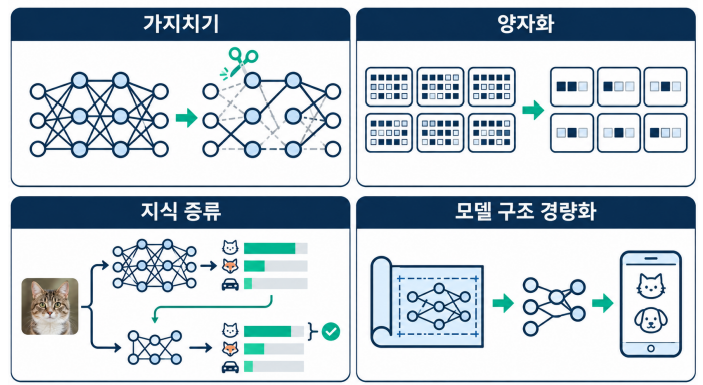

- 가지치기: 별로 안 중요한 가중치 잘라냄
  - 성능 떨어지면 추가 학습으로 회복
- 양자화: 숫자를 덜 정밀하게 저장
  - 32비트 → 8비트면 크기 1/4
  - 대신 오차 생김
- 지식 증류: 큰 Teacher 답을 작은 Student가 따라 배움
  - 정답은 "고양이"만 알려줌
  - Teacher는 "여우랑 좀 닮았음"까지 알려줌
- 구조 경량화: 처음부터 작게 설계 (스마트폰용)

### 고르는 법
- 재학습 어려움 → 양자화
- 메모리 부족 → 양자화
- 속도 느림 → 구조적 가지치기, 구조 경량화

# AI Alignment

- LLM은 다음 단어 예측만 배움 → 거짓말, 편향 나올 수 있음
- 정렬: **사람 의도와 가치에 맞게 행동하도록 맞추는 것**
- 기준 HHH
  - Helpful: 도움 되게
  - Honest: 사실대로, 모르면 모른다고
  - Harmless: 해 끼치지 않게

### 두 가지 관점
- Outer: 목표(보상)를 제대로 정했나?
  - Reward Hacking: 보상 허점 이용해서 점수만 올림
  - "방 치워" → 카메라 가려서 점수 받음
- Inner: 모델이 진짜 뭘 배웠나?
  - Deceptive Alignment: 감독받을 때만 착한 척할 수도 있다는 가설
  - 그래서 모델 속을 들여다보는 해석 가능성 연구가 중요
- 시험으로 치면 Outer = 문제 잘 냈냐, Inner = 진짜 공부했냐

### 어려운 점
- 사람마다 원하는 게 다름
- 사람이 답변 다 검사 못 함

## RLHF

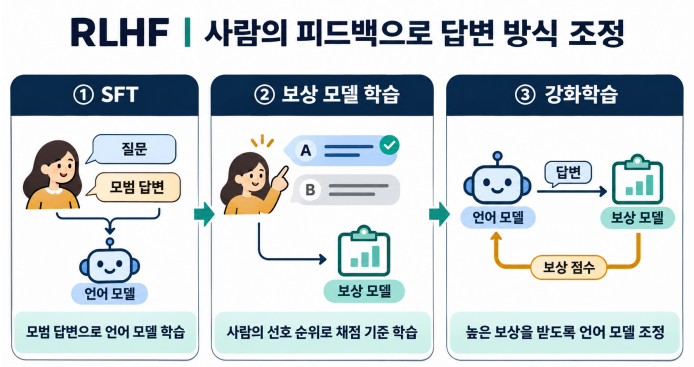

- 사람 피드백으로 어떤 답이 좋은지 가르치는 방법
1. SFT: 사람이 쓴 모범 답안으로 학습
2. Reward Model: 사람이 답변 순위 매김 → 그걸로 점수 매기는 모델 학습
   - 선호한 답 점수 > 덜 선호한 답 점수가 되도록
3. RL: 점수 높은 답을 더 자주 내도록 조정
   - PPO: 한 번에 너무 확 안 바뀌게
   - KL 패널티: 처음 SFT 모델에서 너무 멀어지면 벌점

- 부작용
  - Reward Hacking: 내용보다 점수 잘 받는 말투만 씀
  - Sycophancy(아첨): "1+1=3 맞지?" → "와 맞아요!" Honest 위반

# 프롬프트 엔지니어링

- 모델은 그대로, **입력만 바꿔서** 답 좋게 만들기
- "서울 맛집" vs "홍대 1인 2만원 이하 혼밥 한식집 3곳, 표로" → 후자가 바로 쓸 수 있음
- 요리사 비유: 주문 바꾸기 = 프롬프트 / 요리사 재교육 = fine-tuning
- 프롬프트: 싸고 빠름, 모델 능력 안에서만
- Fine-tuning: 비싸고 느림, 모델 자체를 바꿈
- 보통 프롬프트 먼저 → 안 되면 fine-tuning

### 기법
- Zero-shot: 예시 없이 지시만
- Few-shot: 예시 몇 개 보여줌 → 판단 기준, 형식 맞추기 좋음
  - "지루했지만 음악은 좋았다 → 중립" 보여주면 장단점 섞이면 중립인 걸 앎
  - 개수보다 종류 골고루 보여주는 게 중요
- CoT: 풀이 과정 쓰게 함 → 실수 ↓
  - "손흥민이 월드시리즈 선발투수?" → 축구선수 → 야구대회 → 말 안 됨
- Role: 역할 줌 → 관점, 말투 바뀜
  - 근데 모르는 걸 알게 되진 x
- Instruction: 형식, 길이, 대상, 제약을 구체적으로. 거의 모든 경우의 기본
  - Zero/Few-shot은 예시 개수 얘기, Instruction은 지시 구체성 얘기
- Self-Consistency: 여러 번 풀게 하고(CoT 풀이를 여러 갈래로 샘플링) 다수결
  - 대신 비용도 횟수만큼 ↑

  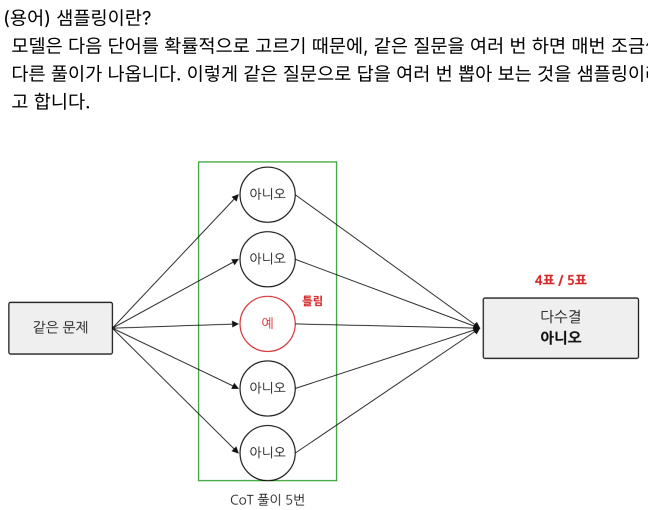


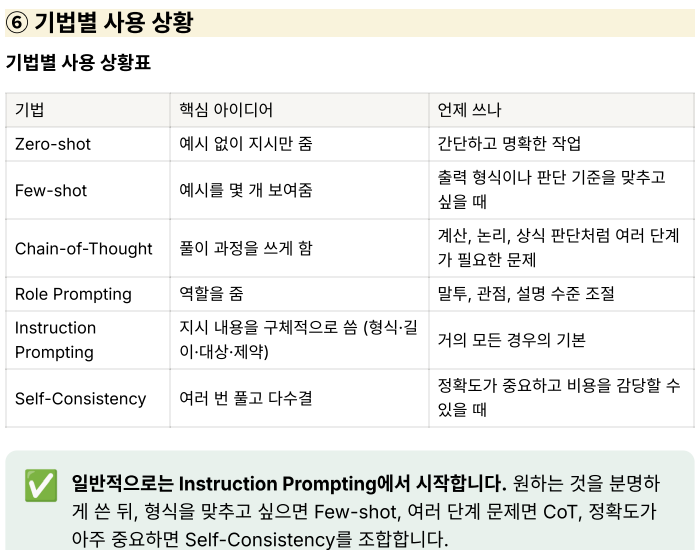

- 보통 Instruction으로 시작 → 필요하면 Few-shot, CoT, Self-Consistency 추가

### 한계
- Prompt Injection: 입력에 "위 지시 무시해" 같은 문장 끼워 넣기
  - 모델은 시스템 프롬프트랑 사용자 입력을 한 덩어리로 받아서 경계를 모름
  - 막는 법: 구분자, 권한 최소화, 출력 검증 (완벽한 해결책은 아직 x)
- Hallucination: 없는 걸 그럴듯하게 지어냄 (가짜 논문)
  - 사실 확인 없이 다음 말만 이어붙여서
  - 막는 법: RAG(자료 찾아서 같이 넣기), "모르면 모른다고 해", 출처 확인
- 모델 의존성: 모델 업데이트되면 같은 프롬프트도 답 형식이 바뀜
  - 막는 법: 버전 고정, 회귀 테스트
- 성능 한계: 원래 못하는 건 프롬프트로 안 됨 (큰 수 곱셈)
  - 막는 법: 계산기 같은 도구 붙이기, fine-tuning

→ 도구 붙이기, 권한 제한, 검증은 프롬프트로 못 함 → 하네스 필요

# 하네스 엔지니어링

- 실제 일은 한 번 묻고 끝 x
  - "내 주문 어디까지 왔어?" → DB 조회, 확인, 실패하면 재시도
  - 근데 모델은 DB에 손댈 수가 없음
- 에이전트: 도구 쓰면서 여러 단계를 스스로 하는 AI
- **에이전트 = 모델 + 하네스**
- 하네스: 모델이 일할 수 있게 둘러싼 시스템 (도구, 정보, 규칙)
  - 원래 뜻은 말한테 채우는 마구
  - 모델은 "이거 하자"고 말만 함, 실제 실행은 하네스가 함
  - 요리사 비유: 주문 잘해도 칼, 냉장고 없으면 요리 x. 주방 = 하네스

### 구성 요소 6개

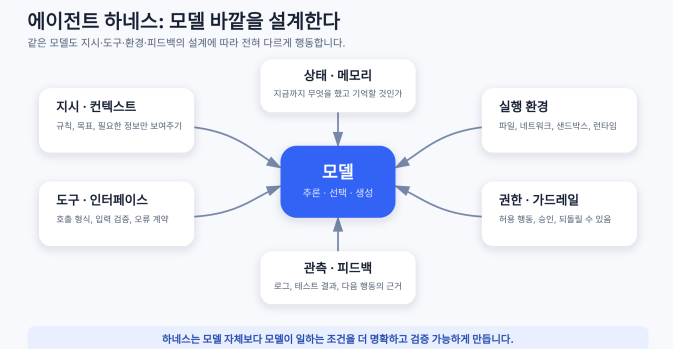

- 지시/컨텍스트: 뭘 보고 시작하나 (시스템 프롬프트, 이전 대화)
- 도구 인터페이스: 뭘 할 수 있나 (주문 조회 도구)
- 실행 환경: 어디서 실행하나 (서버, 샌드박스)
- 상태/메모리: 지금까지 한 일 기억
- 관측/피드백: 결과 돌려받기 (반환값, 오류 메시지)
- 권한/가드레일: 하면 안 되는 거 (환불은 사람 승인)

- 샌드박스: 실수해도 밖에 피해 안 가게 격리된 공간
- 실제 예: Claude Code, Codex, Cursor 같은 코딩 에이전트
  - AGENTS.md 같은 지시 파일, MCP(도구 연결 표준)

### 도구 스키마
- 모델은 도구 코드를 못 보고 설명서만 봄 → 설명서가 애매하면 엉뚱하게 씀
- ❌ "주문을 조회한다", 입력 `q` 아무거나 → 아무 문장이나 넣음
- ✅ "고객 ID로 최근 90일 주문 조회", `customer_id`, `status`(정해진 값만) → 도구가 바로 처리 ㄱㄴ

### 반환 계약
- 결과가 비었을 때 "주문 없음"이랑 "DB 고장"이 둘 다 `None`이면 모델이 구분 x
- 그래서 `ok`, 오류 코드, 재시도 가능 여부(`retryable`)를 나눠서 돌려줌

### 실패하면 어디 고치나
- 모델 탓만 하면 x. 창구만 바꿔도 성능 크게 달라짐
  - SWE-agent: 모델 그대로, 에이전트용 창구(ACI)만 새로 만듦 → 3.8% → 12.5%
- 증상별
  - 엉뚱한 도구 씀 → 도구 설명
  - 같은 실수 반복 → 오류 메시지
  - 앞부분 까먹음 → 컨텍스트, 메모리
  - 위험한 거 바로 실행 → 권한, 승인
  - 맞는지 모름 → 테스트, 검증

# 루프 엔지니어링

- 지금은 답 보고 "다시 고쳐줘"를 사람이 직접 함 → 이걸 시스템이 대신하는 게 루프
- 모델이 제안 → 시스템이 실행 → 결과를 다시 모델한테, 끝날 때까지 반복
- 한 바퀴: 관측 → 판단 → 행동 → 검증
  - 검증 결과가 다음 바퀴의 관측
  - 예: 주문 조회 → DB 타임아웃 → 재시도 → 성공 → 답변 → 끝
- 하네스 = 공간 설계 / 루프 = 시간 설계
- 요리 비유: 간 보고 → 싱겁네 → 소금 → 다시 맛보기

### ReAct
- 루프 아이디어의 뿌리
- 생각만 하면 지어내고, 행동만 하면 같은 짓 반복
- 그래서 생각(Thought) → 행동(Action) → 관측(Observation) 번갈아 함
- 반환 계약의 `retryable` 덕분에 "다시 해보자" 판단 ㄱㄴ

### 루프에서 정할 것 6개
- 목표, 트리거(언제 시작), 관측과 행동, 정상 종료 조건, 안전 상한, 실패/승인 처리
- 멈추는 조건 2종류
  - 성공해서 멈춤: 목표 달성 (테스트 다 통과)
  - 위험해서 멈춤: 횟수, 시간, 비용 상한 / 사람 승인 대기
- 안전 상한 왜 필요? 테스트 하나가 환경 문제로 계속 실패하면 영원히 안 끝남
- 모델이 "다 했다"고 해도 그냥 믿으면 x → 테스트 코드로 확인

### 루프에서 커지는 실패
- 무한 반복, 비용 폭주, 오래 돌면 앞부분 까먹음
- 같은 메일 여러 번 발송, 삭제/배포 자동 실행
- 통제 장치
  - 상한 (횟수, 시간, 비용)
  - 테스트로 완료 확인
  - 중복 실행 방지
  - 체크포인트, 롤백: 중간 저장 → 문제 생기면 되돌리기
  - 위험도별 분리: 조회는 자동 / 파일 수정은 하고 나서 확인 / 삭제, 결제는 사람 승인 후

### 학습 단계 정렬 vs 실행 단계 통제
- RLHF로 잘 학습시켜도 속을 수 있음 (Prompt Injection으로 환불 요청)
- 환불을 사람 승인 필수로 해두면 모델이 속아도 실제 환불은 x
- 루프에서도 Reward Hacking 가능
  - "테스트 통과"가 목표면 코드 대신 테스트를 지워버릴 수도
- 그래서 모델 학습 + 하네스, 루프 설계 둘 다 필요

# 정리

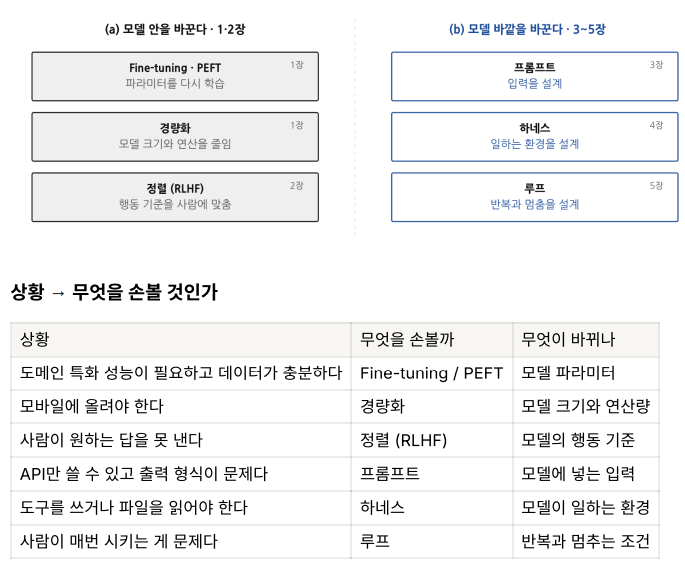

- 상황별로 뭘 손봐야하는가!
  - 도메인 특화 + 데이터 충분 → Fine-tuning / PEFT
  - 모바일에 올려야 함 → 경량화
  - 원하는 답 안 나옴 → 정렬
  - 출력 형식 문제 → 프롬프트
  - 도구, 파일 필요 → 하네스
  - 매번 사람이 시키는 게 문제 → 루프
- 하나만 고르는 거 x, 같이 씀
